# AI, Data Science and Software Development Employment in the USA (May 2023)

**GitHub repository:** `https://github.com/sazalila39/Data_Vis_CA1_2026.git` (access granted to `tahmed1986`)

**4-minute video walkthrough (Google Drive, "Anyone with the link"):** `PASTE YOUR VIDEO LINK HERE`

---

## Introduction
This notebook uses the US Bureau of Labor Statistics (BLS) **Occupational Employment and Wage Statistics (OEWS)** "all data" file for **May 2023**, the latest release at the time of the assignment. It holds about 413,000 rows (national, state and metro areas, by industry and occupation). The goal is to find out what the data says about employment in **AI, Data Science and Software Development**.

**A note on "AI jobs".** The Standard Occupational Classification (SOC) used by BLS has no "AI Engineer" code. I use two proxies for AI work: **Data Scientists** (15-2051) and **Computer and Information Research Scientists** (15-1221, the category that includes AI and machine-learning researchers). I add the other mathematical occupations (statisticians, operations research analysts, mathematicians) to form an **AI & Data Science** family. I compare it with a **Software Development** family (software developers, programmers, QA/testers, web developers) and an **Other IT** family (security, database, network and systems roles) for context.

**Notebook structure**
1. Setup and data preparation
2. Eight visualisations, each with an *objective*, a *why this chart* and a *what I learned* section
3. **Challenge:** employment trends over time using additional BLS yearly datasets
4. Conclusions and limitations

## 1. Setup and data preparation
Only the relevant columns are loaded. BLS marks suppressed or top-coded values with `*`, `**` and `#`, so I convert those to `NaN` to keep the numeric columns numeric. The data is then split into three slices that avoid double counting:

* **`nat`**: national, all industries, detailed occupations (used for most charts)
* **`state`**: state level, all industries (used for the geographic chart)
* **`sector`**: national, split by 2-digit NAICS industry sector (used for the industry chart)

The data file is read from the same folder as this notebook (set `DATA_DIR` in the setup cell to change this) and is **not** included in the submission.

In [29]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.labelsize": 11})

# Folder that holds the BLS "all data" workbooks (same folder as the notebook; NOT uploaded with the submission).
DATA_DIR = os.environ.get("OES_DATA_DIR", ".")
FILE_2023 = os.path.join(DATA_DIR, "all_data_M_2023.xlsx")

# Consistent colourrs for the three occupation families used throughout the notebook
PALETTE = {"AI & Data Science": "#7B3FE4",
           "Software Development": "#1F9E89",
           "Other IT": "#9AA5B1"}

In [30]:
NUMERIC = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "H_MEAN", "A_MEAN",
           "H_MEDIAN", "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]
KEEP = ["AREA", "AREA_TITLE", "AREA_TYPE", "NAICS", "NAICS_TITLE", "I_GROUP", "OWN_CODE",
        "OCC_CODE", "OCC_TITLE", "O_GROUP"] + NUMERIC

raw = pd.read_excel(FILE_2023, sheet_name=0, usecols=KEEP, dtype={"NAICS": str})

# BLS uses '*', '**' and '#' for suppressed / top-coded values, convert to NaN so they are numeric
for c in NUMERIC:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 413,327   Columns: 21


,AREA,AREA_TITLE,AREA_TYPE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,...,JOBS_1000,LOC_QUOTIENT,H_MEAN,A_MEAN,H_MEDIAN,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90
0,99,U.S.,1,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,...,NaN,NaN,31.48,65470.0,23.11,29050.0,35660.0,48060.0,76980.0,121470.0
1,99,U.S.,1,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,...,NaN,NaN,66.23,137750.0,56.19,54550.0,78330.0,116880.0,169090.0,231620.0
2,99,U.S.,1,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,...,NaN,NaN,65.43,136100.0,49.74,46400.0,66170.0,103460.0,165500.0,NaN
3,99,U.S.,1,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,broad,...,NaN,NaN,124.47,258900.0,99.37,80000.0,130840.0,206680.0,NaN,NaN
4,99,U.S.,1,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,detailed,...,NaN,NaN,124.47,258900.0,99.37,80000.0,130840.0,206680.0,NaN,NaN


In [31]:
# --- Occupation catalogue -------------------------------------------------------------
# SOC 2018 has no "AI Engineer" code. Closest proxies: Data Scientists and Computer &
# Information Research Scientists (where AI / machine-learning researchers are classified).
OCC = {
    "15-2051": ("Data Scientists",                     "AI & Data Science"),
    "15-1221": ("Computer & Info. Research Scientists","AI & Data Science"),
    "15-2041": ("Statisticians",                       "AI & Data Science"),
    "15-2031": ("Operations Research Analysts",        "AI & Data Science"),
    "15-2021": ("Mathematicians",                      "AI & Data Science"),
    "15-1252": ("Software Developers",                 "Software Development"),
    "15-1251": ("Computer Programmers",                "Software Development"),
    "15-1253": ("Software QA Analysts & Testers",      "Software Development"),
    "15-1254": ("Web Developers",                      "Software Development"),
    "15-1211": ("Computer Systems Analysts",           "Other IT"),
    "15-1212": ("Information Security Analysts",       "Other IT"),
    "15-1231": ("Network Support Specialists",         "Other IT"),
    "15-1241": ("Network Architects",                  "Other IT"),
    "15-1242": ("Database Administrators",             "Other IT"),
    "15-1243": ("Database Architects",                 "Other IT"),
    "15-1244": ("Network & Systems Administrators",    "Other IT"),
}
cat = pd.DataFrame(OCC, index=["Occupation", "Family"]).T.rename_axis("OCC_CODE").reset_index()

# --- Three slices of the data ------------------------------------------------------------
# 1) National, all industries, detailed occupations
nat = raw[(raw.AREA_TYPE == 1) & (raw.NAICS == "000000") & (raw.O_GROUP == "detailed")]
# 2) State level, all industries
state = raw[(raw.AREA_TYPE == 2) & (raw.NAICS == "000000")]
# 3) National, by 2-digit NAICS sector
sector = raw[(raw.AREA_TYPE == 1) & (raw.I_GROUP == "sector")]

focus = nat.merge(cat, on="OCC_CODE")
focus = focus.assign(Employment=focus.TOT_EMP)
print("Focus occupations found:", len(focus), "of", len(cat))
print(f"Total US employment in the data : {raw.loc[raw.OCC_CODE=='00-0000'].query('AREA_TYPE==1 and NAICS==\"000000\"').TOT_EMP.iloc[0]:,.0f}")
focus[["OCC_CODE", "Occupation", "Family", "TOT_EMP", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

Focus occupations found: 16 of 16
Total US employment in the data : 151,853,870


,OCC_CODE,Occupation,Family,TOT_EMP,A_MEDIAN
9,15-1252,Software Developers,Software Development,1656880.0,132270.0
0,15-1211,Computer Systems Analysts,Other IT,498810.0,103800.0
7,15-1244,Network & Systems Administrators,Other IT,323020.0,95360.0
10,15-1253,Software QA Analysts & Testers,Software Development,203040.0,101800.0
15,15-2051,Data Scientists,AI & Data Science,192710.0,108020.0
1,15-1212,Information Security Analysts,Other IT,175350.0,120360.0
4,15-1241,Network Architects,Other IT,174100.0,129840.0
3,15-1231,Network Support Specialists,Other IT,158720.0,71530.0
8,15-1251,Computer Programmers,Software Development,120370.0,99700.0
13,15-2031,Operations Research Analysts,AI & Data Science,117880.0,83640.0


## 2. Visualisations

### Visualisation 1: Horizontal bar chart, employment by occupation
**Objective (comparison):** compare how many people work in each AI, data and software occupation, to see the relative size of the AI & Data Science workforce against software development.

**Why a horizontal bar chart:** employment is a numeric quantity compared across 16 named categories. Bars make length comparison easy. Horizontal bars give the long occupation names room, and sorting by size gives a ranking. Colour marks the occupation family so the chart answers the family question without extra labels. Pie or line charts would not suit this ranking task.

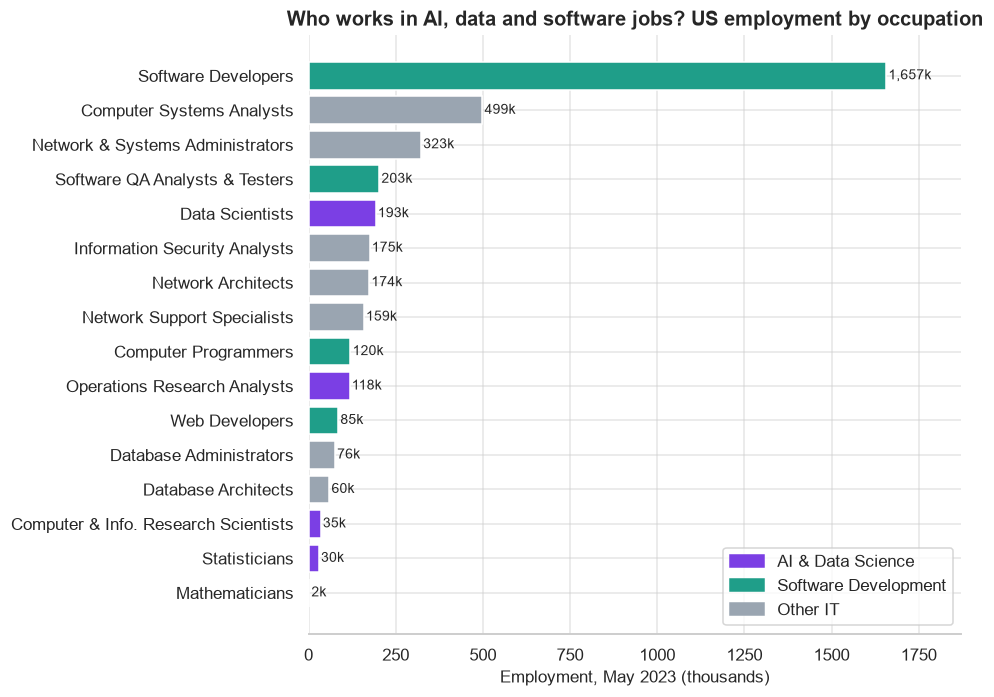

Family
AI & Data Science         377,970
Other IT                1,466,060
Software Development    2,065,640

Data Scientists as % of Software Developers: 11.6


In [32]:
d = focus.sort_values("TOT_EMP")
fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(d.Occupation, d.TOT_EMP / 1000, color=d.Family.map(PALETTE))
for b, v in zip(bars, d.TOT_EMP / 1000):
    ax.text(v + 6, b.get_y() + b.get_height() / 2, f"{v:,.0f}k", va="center", fontsize=9)
ax.set_xlabel("Employment, May 2023 (thousands)")
ax.set_title("Who works in AI, data and software jobs? US employment by occupation")
ax.set_xlim(0, d.TOT_EMP.max() / 1000 * 1.13)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETTE.values()]
ax.legend(handles, PALETTE.keys(), loc="lower right", frameon=True)
sns.despine(left=True)
plt.tight_layout(); plt.show()

fam = focus.groupby("Family").TOT_EMP.sum()
print((fam.map("{:,.0f}".format)).to_string())
print("\nData Scientists as % of Software Developers:",
      round(focus.set_index("OCC_CODE").TOT_EMP["15-2051"] / focus.set_index("OCC_CODE").TOT_EMP["15-1252"] * 100, 1))

**What I learned about AI employment**
* **Software Developers dominate** with about **1.66 million** workers, roughly 8.6 times the **192,710 Data Scientists**. In raw headcount, AI-adjacent work is still a small niche. Data Scientists equal only about **11.6%** of software developer employment.
* The whole AI & Data Science family has about **378,000** jobs, compared with about **2.07 million** in software development.
* **Computer and Information Research Scientists**, the closest proxy for AI/ML research, number only **35,210**. Cutting-edge AI research is a very small workforce compared with applied software and data roles.

### Visualisation 2: Donut (pie) charts, composition of the tech workforce
**Objective (composition):** show the *share* each family holds of the 16 tech occupations, and the make-up of the AI & Data Science family itself.

**Why donut charts:** the question is about parts of a whole with few categories (three families, then five occupations), which is where pie-style charts work. Two donuts side by side give a zoom-in from the whole to one family. I keep them to the families because pies become unreadable with many slices (that was visualisation 1's job).

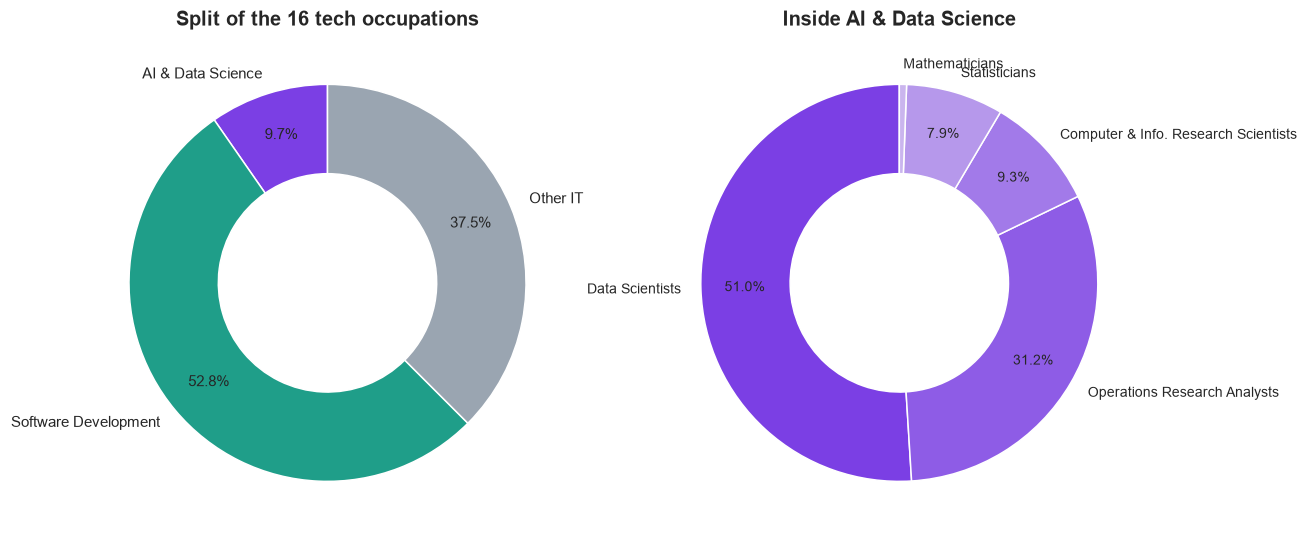

Occupation
Data Scientists                         192,710
Operations Research Analysts            117,880
Computer & Info. Research Scientists     35,210
Statisticians                            29,950
Mathematicians                            2,220


In [33]:
fam = focus.groupby("Family").TOT_EMP.sum().reindex(list(PALETTE))
ai = focus[focus.Family == "AI & Data Science"].set_index("Occupation").TOT_EMP.sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
axes[0].pie(fam, labels=fam.index, colors=[PALETTE[k] for k in fam.index], autopct="%1.1f%%",
            startangle=90, pctdistance=0.78, wedgeprops=dict(width=0.45, edgecolor="white"),
            textprops={"fontsize": 10})
axes[0].set_title("Split of the 16 tech occupations")

shades = sns.light_palette(PALETTE["AI & Data Science"], n_colors=len(ai) + 2, reverse=True)[:-2]
axes[1].pie(ai, labels=ai.index, colors=shades, autopct=lambda p: f"{p:.1f}%" if p > 4 else "",
            startangle=90, pctdistance=0.78, wedgeprops=dict(width=0.45, edgecolor="white"),
            textprops={"fontsize": 9})
axes[1].set_title("Inside AI & Data Science")
plt.tight_layout(); plt.show()
print(ai.map("{:,.0f}".format).to_string())

**What I learned about AI employment**
* AI & Data Science is only **about 9.7%** of these 16 tech occupations. Software Development is **52.8%** and Other IT is **37.5%**.
* Inside AI & Data Science, **Data Scientists are the largest group (51%)**. **Operations Research Analysts** are a surprising **31%**, which shows that "data science" employment is partly traditional analytics and optimisation roles. Computer/Information Research Scientists are **9.3%**, Statisticians **7.9%** and Mathematicians only **0.6%**.
* Together, the 16 occupations are about **3.9 million jobs, around 2.6% of all 151.9 million US jobs**.

### Visualisation 3: Range plot, salary distribution by occupation
**Objective (comparison and distribution):** compare *pay level* and *pay spread* for each AI, data and software occupation, and benchmark them against the typical US worker.

**Why a range plot:** BLS gives the 10th, 25th, 50th, 75th and 90th wage percentiles. A single average would hide the spread, and a standard box plot needs raw data, which is not available here. A range plot (thin line = 10th to 90th percentile, thick bar = middle 50%, dot = median) shows centre and spread in one view. The red line adds the all-occupations median as a reference.

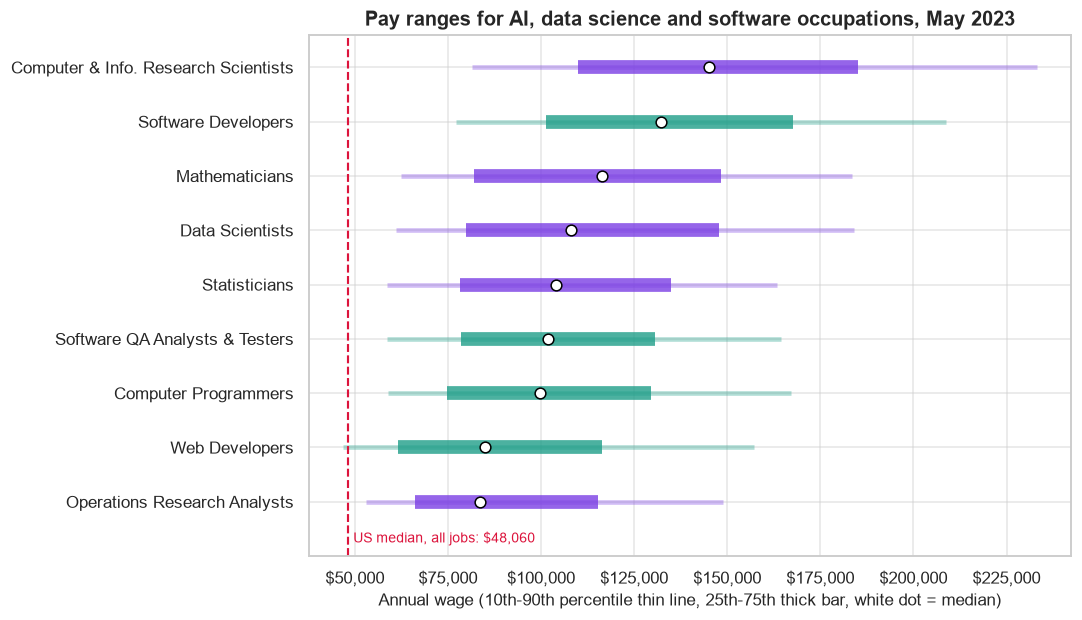

                          Occupation  A_PCT10  A_MEDIAN  A_PCT90
Computer & Info. Research Scientists  81450.0  145080.0 233110.0
                 Software Developers  77020.0  132270.0 208620.0
                      Mathematicians  62260.0  116440.0 183500.0
                     Data Scientists  61070.0  108020.0 184090.0
                       Statisticians  58690.0  104110.0 163360.0
      Software QA Analysts & Testers  58740.0  101800.0 164520.0
                Computer Programmers  58950.0   99700.0 167230.0
                      Web Developers  46850.0   84960.0 157280.0
        Operations Research Analysts  52930.0   83640.0 148920.0


In [34]:
core = focus[focus.Family != "Other IT"].sort_values("A_MEDIAN").reset_index(drop=True)
us_med = raw[(raw.OCC_CODE == "00-0000") & (raw.AREA_TYPE == 1) & (raw.NAICS == "000000")].A_MEDIAN.iloc[0]

fig, ax = plt.subplots(figsize=(10, 5.8))
for i, r in core.iterrows():
    col = PALETTE[r.Family]
    ax.hlines(i, r.A_PCT10, r.A_PCT90, color=col, lw=3, alpha=.35)
    ax.hlines(i, r.A_PCT25, r.A_PCT75, color=col, lw=9, alpha=.8)
    ax.plot(r.A_MEDIAN, i, "o", color="white", mec="black", ms=7, zorder=5)
ax.axvline(us_med, color="crimson", ls="--", lw=1.4)
ax.text(us_med + 1500, -0.75, f"US median, all jobs: ${us_med:,.0f}", color="crimson", fontsize=9)
ax.set_yticks(range(len(core))); ax.set_yticklabels(core.Occupation)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Annual wage (10th-90th percentile thin line, 25th-75th thick bar, white dot = median)")
ax.set_title("Pay ranges for AI, data science and software occupations, May 2023")
ax.set_ylim(-1, len(core) - .4)
plt.tight_layout(); plt.show()

print(core[["Occupation", "A_PCT10", "A_MEDIAN", "A_PCT90"]].sort_values("A_MEDIAN", ascending=False).to_string(index=False))

**What I learned about AI employment**
* **Computer and Information Research Scientists** (AI/ML research) earn the most: median **$145,080**, and the top 10% earn **over $233,000**. Software Developers follow at **$132,270**.
* **Data Scientists** have a median of **$108,020**, about **2.2 times** the US median of **$48,060**. Their range is wide: from about **$61,000** (10th percentile) to **$184,000** (90th percentile), so experience, industry and location matter a lot.
* **Operations Research Analysts** ($83,640) and **Web Developers** ($84,960) are the lowest-paid in this group, but still well above the all-jobs median.
* Research roles pay more than applied data roles, a pay premium for deep specialisation.

### Visualisation 4: Scatter plot, employment size vs. pay for every US occupation
**Objective (relationship / investigation):** test whether tech occupations are special in the whole labour market, and whether bigger occupations tend to pay more or less.

**Why a scatter plot:** both variables are numeric and I want to see the *relationship* and where specific points sit against the full cloud of about 800 occupations. Employment is on a log scale because occupation sizes range from hundreds to millions of workers. The grey cloud gives context and the coloured points are the focus.

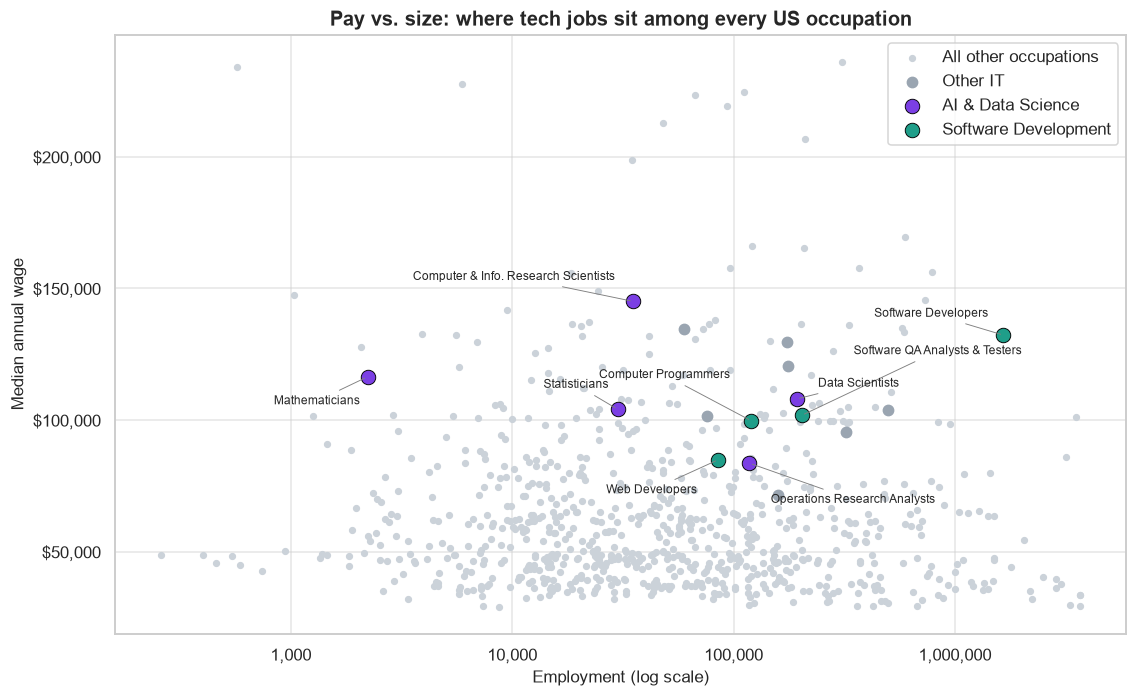

Spearman correlation between employment size and median pay (all other occupations): -0.08


In [35]:
rest = nat[~nat.OCC_CODE.isin(cat.OCC_CODE)].dropna(subset=["TOT_EMP", "A_MEDIAN"])
hi = focus[focus.Family != "Other IT"].dropna(subset=["A_MEDIAN"])
oth = focus[focus.Family == "Other IT"].dropna(subset=["A_MEDIAN"])

fig, ax = plt.subplots(figsize=(10.5, 6.5))
ax.scatter(rest.TOT_EMP, rest.A_MEDIAN, s=14, color="#CBD2D9", label="All other occupations", zorder=1)
ax.scatter(oth.TOT_EMP, oth.A_MEDIAN, s=45, color=PALETTE["Other IT"], label="Other IT", zorder=2)
for fam_name, g in hi.groupby("Family"):
    ax.scatter(g.TOT_EMP, g.A_MEDIAN, s=90, color=PALETTE[fam_name], edgecolor="black", lw=.6,
               label=fam_name, zorder=3)
offsets = {"Data Scientists": (14, 8), "Software Developers": (-10, 12), "Computer Programmers": (-14, 28),
           "Web Developers": (-14, -22), "Statisticians": (-6, 14), "Operations Research Analysts": (14, -26),
           "Computer & Info. Research Scientists": (-12, 14), "Mathematicians": (-5, -18),
           "Software QA Analysts & Testers": (34, 40)}
for _, r in hi.iterrows():
    dx, dy = offsets.get(r.Occupation, (6, 6))
    ax.annotate(r.Occupation, (r.TOT_EMP, r.A_MEDIAN), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, ha="left" if dx > 0 else "right",
                arrowprops=dict(arrowstyle="-", color="gray", lw=.6))
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Employment (log scale)"); ax.set_ylabel("Median annual wage")
ax.set_title("Pay vs. size: where tech jobs sit among every US occupation")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout(); plt.show()

r = rest.A_MEDIAN.corr(np.log10(rest.TOT_EMP), method="spearman")
print(f"Spearman correlation between employment size and median pay (all other occupations): {r:.2f}")

**What I learned about AI employment**
* Among all other occupations there is **practically no relationship between occupation size and pay** (Spearman correlation of about **-0.08**). Being a large occupation does not make it well paid.
* **Software Developers stand out**: at about 1.66 million workers they are among the rare occupations that are both very large and highly paid.
* Data and AI roles mostly sit well **above the main cloud** of occupations (the cloud is concentrated between $30k and $70k). Among occupations of similar size, they are paid far better.

### Visualisation 5: Histogram, where tech pay ranks among all occupations
**Objective (distribution / ranking):** show how the median pay of AI, data and software jobs ranks within the whole distribution of occupational pay.

**Why a histogram with reference lines:** a histogram shows the *shape* of a distribution (here right-skewed, with most occupations at lower pay and a long high-pay tail). Vertical lines mark where chosen occupations fall, which gives a percentile rank that no bar or pie chart could show as clearly.

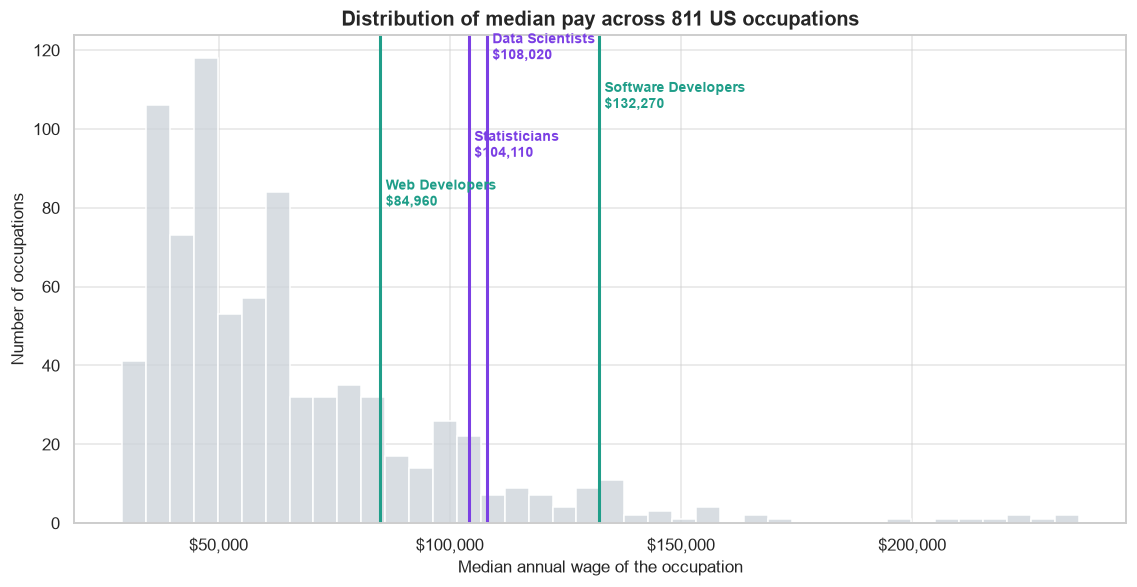

Data Scientists        earns more than  92.0% of occupations
Software Developers    earns more than  95.7% of occupations
Statisticians          earns more than  90.3% of occupations
Web Developers         earns more than  80.9% of occupations


In [36]:
allmed = nat.dropna(subset=["A_MEDIAN"])
fig, ax = plt.subplots(figsize=(10.5, 5.5))
sns.histplot(allmed.A_MEDIAN, bins=40, color="#CBD2D9", edgecolor="white", ax=ax)
marks = {"Data Scientists": "15-2051", "Software Developers": "15-1252",
         "Statisticians": "15-2041", "Web Developers": "15-1254"}
ymax = ax.get_ylim()[1]
for i, (name, code) in enumerate(marks.items()):
    v = allmed.loc[allmed.OCC_CODE == code, "A_MEDIAN"].iloc[0]
    fam_name = OCC[code][1]
    ax.axvline(v, color=PALETTE[fam_name], lw=2)
    ax.text(v + 1200, ymax * (0.95 - i * 0.1), f"{name}\n${v:,.0f}", color=PALETTE[fam_name], fontsize=9, fontweight="bold")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Median annual wage of the occupation"); ax.set_ylabel("Number of occupations")
ax.set_title(f"Distribution of median pay across {len(allmed)} US occupations")
plt.tight_layout(); plt.show()

for name, code in marks.items():
    v = allmed.loc[allmed.OCC_CODE == code, "A_MEDIAN"].iloc[0]
    print(f"{name:22s} earns more than {(allmed.A_MEDIAN < v).mean()*100:5.1f}% of occupations")

**What I learned about AI employment**
* The distribution of occupational pay is **right-skewed**, with most of the 811 occupations clustered at the lower end.
* **Data Scientists earn more than about 92% of all occupations**, Statisticians more than **90%**, Web Developers more than **81%** and Software Developers more than **96%**.
* Even the *lowest* paid of these jobs sits in the top fifth of pay. AI and data skills are rewarded with a strong, consistent pay premium.

### Visualisation 6: Heatmap, geography of tech jobs by state
**Objective (geographic comparison):** find which states have the highest *concentration* of AI, data and software jobs (jobs per 1,000 workers), not just the most jobs.

**Why a heatmap:** I compare many states (rows) across several occupations (columns), and each cell is one number. Colour intensity lets the eye find hotspots across 90 values at once, and printed values keep it exact. I use jobs per 1,000 workers rather than raw counts so big states such as California do not win only because of size.

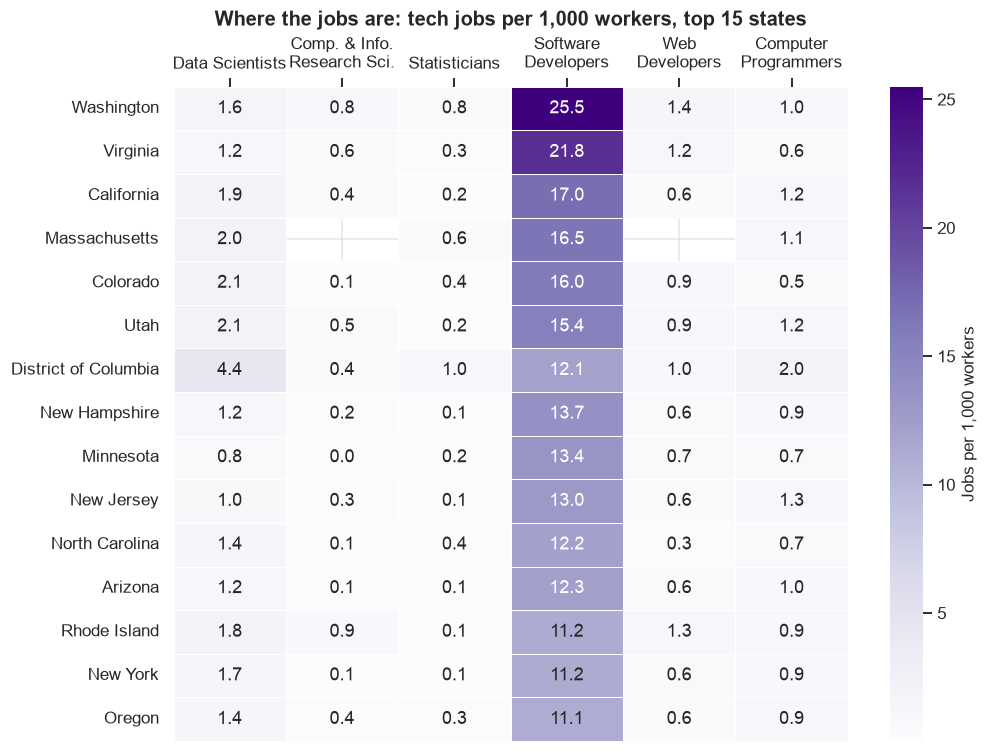

Top 5 states by number of Data Scientists:
  AREA_TITLE  TOT_EMP  JOBS_1000  A_MEDIAN
  California  33220.0      1.851  133690.0
       Texas  20560.0      1.517  100100.0
    New York  16390.0      1.745  128890.0
     Florida   8400.0      0.878   95360.0
Pennsylvania   7490.0      1.259   97260.0

Share of all US Data Scientists in the top 5 states: 44.7%


In [37]:
heat_occ = {"15-2051": "Data Scientists", "15-1221": "Comp. & Info.\nResearch Sci.", "15-2041": "Statisticians",
            "15-1252": "Software\nDevelopers", "15-1254": "Web\nDevelopers", "15-1251": "Computer\nProgrammers"}
s = state[state.OCC_CODE.isin(heat_occ)].pivot_table(index="AREA_TITLE", columns="OCC_CODE", values="JOBS_1000")
s = s[list(heat_occ)]
s["score"] = s["15-2051"].fillna(0) + s["15-1252"].fillna(0)
top = s.sort_values("score", ascending=False).head(15).drop(columns="score")
top.columns = [heat_occ[c] for c in top.columns]

fig, ax = plt.subplots(figsize=(9.5, 7))
sns.heatmap(top, annot=True, fmt=".1f", cmap="Purples", linewidths=.5, cbar_kws={"label": "Jobs per 1,000 workers"}, ax=ax)
ax.set_ylabel(""); ax.set_xlabel("")
ax.xaxis.tick_top()
ax.set_title("Where the jobs are: tech jobs per 1,000 workers, top 15 states", pad=40)
plt.tight_layout(); plt.show()

ds = state[state.OCC_CODE == "15-2051"].dropna(subset=["TOT_EMP"]).sort_values("TOT_EMP", ascending=False)
print("Top 5 states by number of Data Scientists:")
print(ds[["AREA_TITLE", "TOT_EMP", "JOBS_1000", "A_MEDIAN"]].head(5).to_string(index=False))
print(f"\nShare of all US Data Scientists in the top 5 states: {ds.TOT_EMP.head(5).sum() / ds.TOT_EMP.sum() * 100:.1f}%")

**What I learned about AI employment**
* **Data science is geographically concentrated.** California (33,220), Texas (20,560), New York (16,390), Florida (8,400) and Pennsylvania (7,490) hold **44.7%** of all US Data Scientists.
* Relative to state size, the **District of Columbia** has the highest concentration of Data Scientists (**4.4 per 1,000 workers**), well ahead of Utah, Colorado, Massachusetts and California (about **1.9 to 2.1**). Government and consulting demand probably drives DC.
* For **software developers**, the most concentrated states are **Washington (25.5 per 1,000)**, **Virginia (21.8)**, **California (17.0)**, **Massachusetts (16.5)** and **Colorado (16.0)**.
* Pay follows the hotspots: Data Scientists' median is **$133,690 in California**, compared with **$100,100 in Texas** and **$95,360 in Florida**.

### Visualisation 7: Stacked horizontal bar chart, top 10 states for AI & Data Science jobs
**Objective (ranking / geographic comparison):** identify which states employ the most AI & Data Science workers in absolute numbers, and whether the mix of Data Scientists and AI/ML research scientists differs between states. Visualisation 6 showed *density*; this chart shows *volume*.

**Why a stacked horizontal bar:** the states are named categories, so horizontal bars keep the labels readable and give a clear ranking. Stacking splits each state's total into its two components (Data Scientists and research scientists) without adding a second chart. Limiting it to the top 10 keeps it legible.

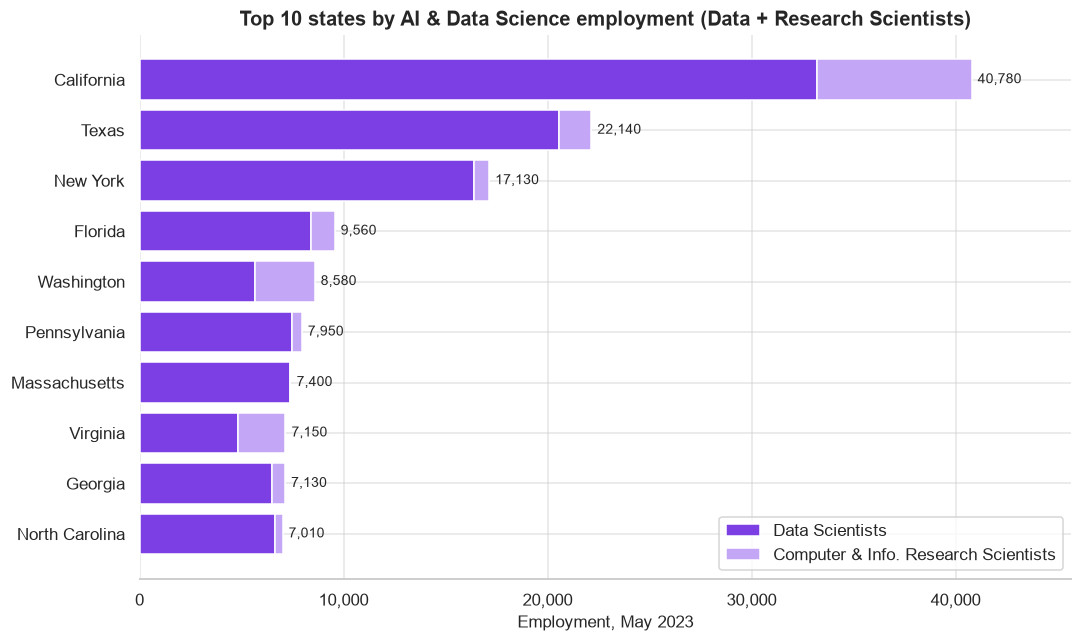

Top 10 states hold 60.9% of these jobs (all states total 221,290).
OCC_CODE        15-2051  15-1221  Total
AREA_TITLE                             
California        33220     7560  40780
Texas             20560     1580  22140
New York          16390      740  17130
Florida            8400     1160   9560
Washington         5640     2940   8580
Pennsylvania       7490      460   7950
Massachusetts      7400        0   7400
Virginia           4810     2340   7150
Georgia            6510      620   7130
North Carolina     6640      370   7010


In [38]:
# Top 10 states by combined Data Scientist + Computer/Information Research Scientist employment
ai_states = state[state.OCC_CODE.isin(["15-2051", "15-1221"])]
piv = ai_states.pivot_table(index="AREA_TITLE", columns="OCC_CODE", values="TOT_EMP", aggfunc="sum").fillna(0)
piv["Total"] = piv.sum(axis=1)
top10 = piv.sort_values("Total", ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10.index, top10["15-2051"], color=PALETTE["AI & Data Science"], label="Data Scientists")
ax.barh(top10.index, top10["15-1221"], left=top10["15-2051"], color="#C3A6F5", label="Computer & Info. Research Scientists")
for y, (t) in enumerate(top10["Total"]):
    ax.text(t + 300, y, f"{t:,.0f}", va="center", fontsize=9)
ax.set_xlabel("Employment, May 2023")
ax.set_title("Top 10 states by AI & Data Science employment (Data + Research Scientists)")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, top10.Total.max() * 1.12)
ax.legend(loc="lower right"); sns.despine(left=True)
plt.tight_layout(); plt.show()

total_us = piv.Total.sum()
print(f"Top 10 states hold {top10.Total.sum() / total_us * 100:.1f}% of these jobs (all states total {total_us:,.0f}).")
print(top10.sort_values("Total", ascending=False)[["15-2051", "15-1221", "Total"]].astype(int).to_string())

**What I learned about AI employment**
* **California is in a league of its own** with about **40,800** Data and AI research scientists, almost double second-placed **Texas (22,100)**. New York (17,100), Florida (9,600) and Washington (8,600) follow.
* The **top 10 states hold about 61%** of the jobs recorded at state level, so this work is concentrated geographically.
* The mix differs by state. **Washington** and **Virginia** have an unusually large share of research scientists (about 2,900 and 2,300), while Texas, New York and Florida are almost entirely Data Scientists. This fits the idea of research hubs (tech companies and government/defence labs) versus business-analytics hubs (finance, energy, healthcare).
* **Caveat:** BLS hides values for small cells. Massachusetts shows no research scientists here because that figure is suppressed, not because there are none, so its bar is understated.

### Visualisation 8: 100% stacked bar chart, which industries employ them?
**Objective (composition across categories):** show which parts of the economy hire Data Scientists, AI/ML research scientists and Software Developers, and whether the three roles are used in the same places.

**Why a 100% stacked bar:** I compare the *shares* of three occupations across the same set of sectors. Normalising each bar to 100% removes the size difference (192k vs 1.66M workers) and puts the focus on *where* they work. Sectors beyond the top six are grouped as "All other sectors" for clarity.

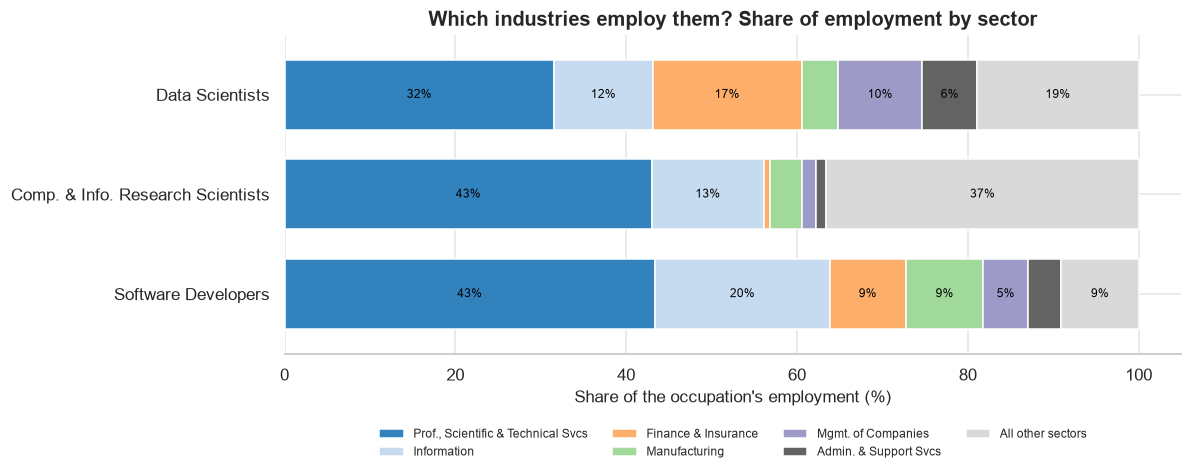

                                    Data Scientists  Comp. & Info. Research Scientists  Software Developers
Sector                                                                                                     
Prof., Scientific & Technical Svcs             31.6                               43.0                 43.4
Information                                    11.5                               13.0                 20.5
Finance & Insurance                            17.4                                0.8                  8.9
Manufacturing                                   4.3                                3.7                  9.1
Mgmt. of Companies                              9.9                                1.6                  5.2
Admin. & Support Svcs                           6.4                                1.2                  3.9
All other sectors                              18.9                               36.6                  9.1


In [39]:
codes = {"15-2051": "Data Scientists", "15-1221": "Comp. & Info. Research Scientists", "15-1252": "Software Developers"}
sec = sector[sector.OCC_CODE.isin(codes)].groupby(["OCC_CODE", "NAICS_TITLE"]).TOT_EMP.sum().reset_index()
sec["share"] = sec.groupby("OCC_CODE").TOT_EMP.transform(lambda x: x / x.sum() * 100)
sec["NAICS_TITLE"] = sec.NAICS_TITLE.replace({
    "Professional, Scientific, and Technical Services": "Prof., Scientific & Technical Svcs",
    "Finance and Insurance": "Finance & Insurance",
    "Educational Services": "Educational Services",
    "Administrative and Support and Waste Management and Remediation Services": "Admin. & Support Svcs",
    "Management of Companies and Enterprises": "Mgmt. of Companies"})

order = sec.groupby("NAICS_TITLE").TOT_EMP.sum().sort_values(ascending=False)
keep = list(order.head(6).index)
sec["Sector"] = np.where(sec.NAICS_TITLE.isin(keep), sec.NAICS_TITLE, "All other sectors")
pv = (sec.groupby(["OCC_CODE", "Sector"]).share.sum().unstack().reindex(columns=keep + ["All other sectors"]))
pv.index = [codes[c] for c in pv.index]
pv = pv.loc[["Data Scientists", "Comp. & Info. Research Scientists", "Software Developers"]]

ax = pv.plot(kind="barh", stacked=True, figsize=(11, 4.6), colormap="tab20c", edgecolor="white", width=.7)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 5 else "" for v in c.datavalues], label_type="center", fontsize=8, color="black")
ax.set_xlabel("Share of the occupation's employment (%)"); ax.set_ylabel("")
ax.set_title("Which industries employ them? Share of employment by sector")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=4, frameon=False, fontsize=8)
ax.invert_yaxis(); sns.despine(left=True)
plt.tight_layout(); plt.show()
print(pv.round(1).T.to_string())

**What I learned about AI employment**
* **Professional, Scientific and Technical Services** (consulting, computer design, research firms) is the top employer for all three roles: **31.6%** of Data Scientists, **43.0%** of research scientists and **43.4%** of software developers.
* **Data Scientists are the most industry-diverse.** **Finance and Insurance** employs **17.4%** of them (only 0.8% of research scientists and 8.9% of software developers), and **Management of Companies** another **9.9%**. Data science is an applied business-analytics job.
* AI/ML **research scientists** are concentrated in professional/technical services (43%) and Information (13%), with a long tail (about 37%) in smaller sectors. They are linked to research and technology producers rather than ordinary businesses.

## 3. Challenge: AI, data and software employment trends over time
**Objective (trend analysis):** the May 2023 file is a *snapshot*. To see **change**, I combine it with the OEWS "All data" files for **May 2019, 2020, 2021 and 2022** from <https://www.bls.gov/oes/tables.htm> (the same "all data" option, different years) and track employment and median pay for the same occupations over five years.

**Why these charts:** a **line chart** is the standard way to show change over time. I *index* employment to 100 in one common year (2021, the first year Data Scientists exist as their own occupation) so occupations of very different size (35k vs 1.9M workers) share one axis, and I add the **all-occupations** line as a benchmark. A second line chart shows median pay. A **bar chart of the compound annual growth rate (CAGR)** then ranks the occupations by growth speed.

**Making the years comparable (important):** BLS changed its occupation codes during this period.
* **May 2019-2020** list *Software Developers* together with *QA Analysts and Testers* (15-1256), and *Web Developers* together with *Digital Interface Designers* (15-1257). From May 2021 these are separate codes, so I **add the separate codes back together** to keep one consistent series, labelled "Software Developers & QA Testers" and "Web Developers & Digital Designers".
* **Data Scientists** (15-2051) only exist as their own code from **May 2021**. Before that they are hidden inside the catch-all 15-2098, which is not comparable, so Data Scientists have **three data points (2021-2023) instead of five**.
* When two codes are added together, the combined median pay is approximated by the employment-weighted average of the two medians.

`load_year()` opens each `all_data_M_<year>.xlsx`, keeps the national all-industry rows and builds these series. A missing file or an occupation that does not exist in a year is skipped instead of breaking the notebook.

In [40]:
# ---------------- CHALLENGE: employment trends over time ----------------
# Earlier yearly workbooks come from https://www.bls.gov/oes/tables.htm ("All data" for each May).
# Save them next to this notebook as all_data_M_<year>.xlsx. They are read locally and are NOT submitted.
YEARS = [2019, 2020, 2021, 2022, 2023]

# BLS changed its occupation codes between releases:
#  * May 2019-2020 list Software Developers together with QA Analysts & Testers (15-1256) and
#    Web Developers together with Digital Interface Designers (15-1257).
#  * From May 2021 they are separate codes (15-1252 + 15-1253, 15-1254 + 15-1255).
#  * "Data Scientists" (15-2051) only exists as its own code from May 2021; before that they sit
#    inside 15-2098 ("...All Other"), which is NOT comparable, so earlier years are left blank.
# So each series below is built from the first matching group of codes, summing codes in the group.
TREND_OCC = {
    # label: (family, [alternative code groups])
    "Data Scientists":                      ("AI & Data Science",    [["15-2051"]]),
    "Computer & Info. Research Scientists": ("AI & Data Science",    [["15-1221"]]),
    "Statisticians":                        ("AI & Data Science",    [["15-2041"]]),
    "Operations Research Analysts":         ("AI & Data Science",    [["15-2031"]]),
    "Software Developers & QA Testers":     ("Software Development", [["15-1252", "15-1253"], ["15-1256"]]),
    "Web Developers & Digital Designers":   ("Software Development", [["15-1254", "15-1255"], ["15-1257"]]),
    "All occupations":                      ("All",                  [["00-0000"]]),
}
WANT = {"AREA", "AREA_TYPE", "NAICS", "OCC_CODE", "OCC_TITLE", "O_GROUP", "TOT_EMP", "A_MEDIAN"}

def load_year(year):
    """National, all-industry employment and median wage for each trend occupation in one year."""
    path = os.path.join(DATA_DIR, f"all_data_M_{year}.xlsx")
    if not os.path.exists(path):
        return None
    df = pd.read_excel(path, sheet_name=0, usecols=lambda c: c.upper() in WANT, dtype=str)
    df.columns = [c.upper() for c in df.columns]
    df = df[df.AREA_TYPE.astype(str).str.strip() == "1"] if "AREA_TYPE" in df else df[df.AREA.astype(str).str.strip() == "99"]
    if "NAICS" in df:
        df = df[df.NAICS.astype(str).str.strip().isin(["000000", "0"])]
    df = df.assign(TOT_EMP=pd.to_numeric(df.TOT_EMP, errors="coerce"), A_MEDIAN=pd.to_numeric(df.A_MEDIAN, errors="coerce"))
    out = []
    for label, (family, groups) in TREND_OCC.items():
        for codes in groups:
            m = df[df.OCC_CODE.isin(codes)].dropna(subset=["TOT_EMP"])
            if len(m):
                emp = m.TOT_EMP.sum()
                # when two codes are merged, the combined median is approximated by the employment-weighted mean
                med = np.average(m.A_MEDIAN, weights=m.TOT_EMP) if m.A_MEDIAN.notna().all() else np.nan
                out.append({"Year": year, "Occupation": label, "Family": family, "TOT_EMP": emp, "A_MEDIAN": med})
                break
    return pd.DataFrame(out)

frames = [f for f in (load_year(y) for y in YEARS) if f is not None and not f.empty]
panel = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=["Year", "Occupation", "Family", "TOT_EMP", "A_MEDIAN"])
years_loaded = sorted(int(y) for y in panel.Year.unique())
HAVE_TREND = len(years_loaded) >= 2

if HAVE_TREND:
    print("Years loaded:", years_loaded)
    display(panel.pivot(index="Occupation", columns="Year", values="TOT_EMP").style.format("{:,.0f}", na_rep="n/a"))
else:
    print("Only", years_loaded or "no", "year(s) found in", DATA_DIR)
    print("Save the earlier 'All data' workbooks as all_data_M_<year>.xlsx in that folder and re-run this section.")

Years loaded: [2019, 2020, 2021, 2022, 2023]


Year,2019,2020,2021,2022,2023
Occupation,,,,,
All occupations,"146,875,480","139,099,570","140,886,310","147,886,000","151,853,870"
Computer & Info. Research Scientists,"30,780","30,220","30,840","33,780","35,210"
Data Scientists,n/a,n/a,"105,980","159,630","192,710"
Operations Research Analysts,"99,680","96,220","98,700","105,080","117,880"
Software Developers & QA Testers,"1,406,870","1,476,800","1,554,300","1,731,210","1,859,920"
Statisticians,"39,090","38,860","31,370","30,780","29,950"
Web Developers & Digital Designers,"148,340","156,220","167,200","185,970","196,410"


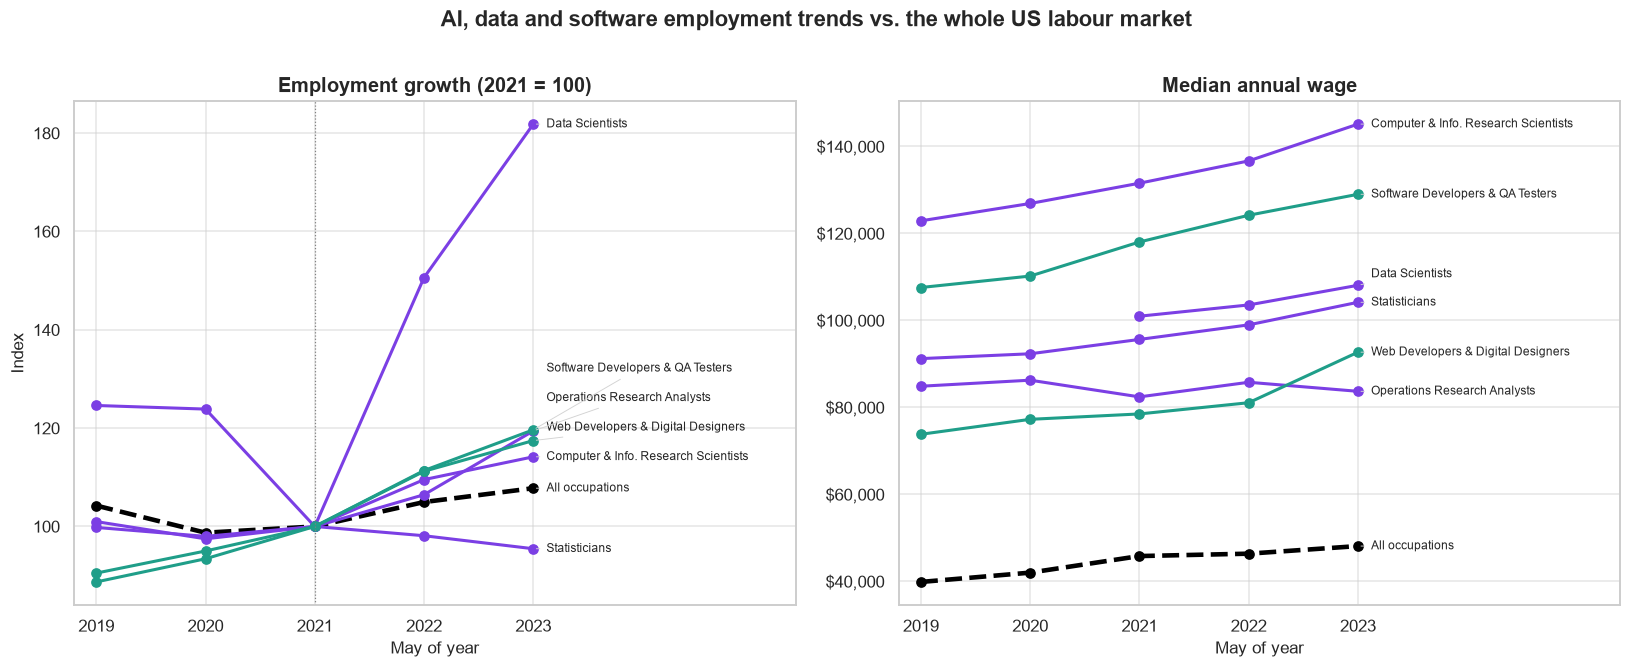

In [41]:
if HAVE_TREND:
    emp = panel.pivot(index="Year", columns="Occupation", values="TOT_EMP")
    wage = panel.pivot(index="Year", columns="Occupation", values="A_MEDIAN")
    # Index every series to 100 in ONE common base year (the first year in which all series exist),
    # so the lines are directly comparable. Data Scientists only exist from 2021, so that is the base.
    base_year = max(emp[c].first_valid_index() for c in emp.columns)
    idx = emp / emp.loc[base_year] * 100

    def end_labels(ax, series, gap):
        """Write each line's name at its right-hand end, nudging labels apart so they never overlap."""
        ends = sorted(((s.dropna().iloc[-1], name, s.dropna().index[-1]) for name, s in series.items()), key=lambda t: t[0])
        ys = [e[0] for e in ends]
        for i in range(1, len(ys)):
            ys[i] = max(ys[i], ys[i - 1] + gap)
        for (y0, name, x), y in zip(ends, ys):
            ax.annotate(name, (x, y0), xytext=(x + .12, y), textcoords="data", fontsize=8, va="center",
                        arrowprops=dict(arrowstyle="-", color="lightgray", lw=.6))

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for occ in emp.columns:
        is_all = occ == "All occupations"
        col = "black" if is_all else PALETTE[panel.loc[panel.Occupation == occ, "Family"].iloc[0]]
        kw = dict(marker="o", lw=3 if is_all else 2, ls="--" if is_all else "-", color=col)
        axes[0].plot(idx.index, idx[occ], **kw)
        axes[1].plot(wage.index, wage[occ], **kw)
    end_labels(axes[0], {c: idx[c] for c in idx.columns}, gap=6)
    end_labels(axes[1], {c: wage[c] for c in wage.columns}, gap=6500)
    axes[0].axvline(base_year, color="gray", lw=.8, ls=":")
    axes[0].set_title(f"Employment growth ({base_year} = 100)"); axes[0].set_ylabel("Index")
    axes[1].set_title("Median annual wage"); axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
    for ax in axes:
        ax.set_xticks(years_loaded); ax.set_xlim(years_loaded[0] - .2, years_loaded[-1] + 2.4); ax.set_xlabel("May of year")
    plt.suptitle("AI, data and software employment trends vs. the whole US labour market", fontweight="bold", y=1.01)
    plt.tight_layout(); plt.show()

,Occupation,From,To,Employment change %,CAGR %,All-jobs CAGR % (same years),Median wage change %,All-jobs wage change % (same years)
0,Data Scientists,2021,2023,+81.8,+34.8,+3.8,+7.0,+5.0
1,Web Developers & Digital Designers,2019,2023,+32.4,+7.3,+0.8,+25.6,+20.7
2,Software Developers & QA Testers,2019,2023,+32.2,+7.2,+0.8,+19.9,+20.7
3,Operations Research Analysts,2019,2023,+18.3,+4.3,+0.8,-1.4,+20.7
4,Computer & Info. Research Scientists,2019,2023,+14.4,+3.4,+0.8,+18.1,+20.7
5,All occupations,2019,2023,+3.4,+0.8,+0.8,+20.7,+20.7
6,Statisticians,2019,2023,-23.4,-6.4,+0.8,+14.2,+20.7


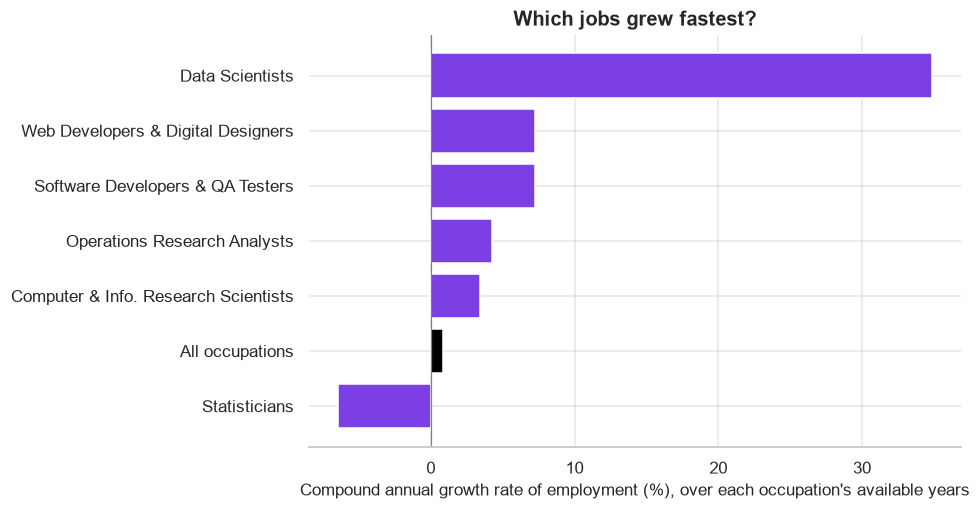

FINDINGS
- Data Scientists (2021-2023): employment +81.8% (+34.8% a year, faster than all jobs at +3.8%); median pay +7.0% vs +5.0% for all jobs.
- Web Developers & Digital Designers (2019-2023): employment +32.4% (+7.3% a year, faster than all jobs at +0.8%); median pay +25.6% vs +20.7% for all jobs.
- Software Developers & QA Testers (2019-2023): employment +32.2% (+7.2% a year, faster than all jobs at +0.8%); median pay +19.9% vs +20.7% for all jobs.
- Operations Research Analysts (2019-2023): employment +18.3% (+4.3% a year, faster than all jobs at +0.8%); median pay -1.4% vs +20.7% for all jobs.
- Computer & Info. Research Scientists (2019-2023): employment +14.4% (+3.4% a year, faster than all jobs at +0.8%); median pay +18.1% vs +20.7% for all jobs.
- Statisticians (2019-2023): employment -23.4% (-6.4% a year, slower than all jobs at +0.8%); median pay +14.2% vs +20.7% for all jobs.


In [42]:
if HAVE_TREND:
    all_emp, all_wage = emp["All occupations"], wage["All occupations"]
    rows = []
    for occ in emp.columns:
        s, w = emp[occ].dropna(), wage[occ].dropna()
        if len(s) < 2: continue
        y0, y1 = s.index[0], s.index[-1]
        n = y1 - y0
        cagr = lambda a, b: ((b / a) ** (1 / n) - 1) * 100
        rows.append({"Occupation": occ, "From": y0, "To": y1,
                     "Employment change %": (s.iloc[-1] / s.iloc[0] - 1) * 100,
                     "CAGR %": cagr(s.iloc[0], s.iloc[-1]),
                     "All-jobs CAGR % (same years)": cagr(all_emp[y0], all_emp[y1]),
                     "Median wage change %": (w.loc[y1] / w.loc[y0] - 1) * 100,
                     "All-jobs wage change % (same years)": (all_wage[y1] / all_wage[y0] - 1) * 100})
    growth = pd.DataFrame(rows).sort_values("CAGR %", ascending=False).reset_index(drop=True)
    display(growth.style.format({c: "{:+.1f}" for c in growth.columns if "%" in c}))

    g = growth.sort_values("CAGR %")
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.barh(g.Occupation, g["CAGR %"], color=["black" if o == "All occupations" else "#7B3FE4" for o in g.Occupation])
    ax.axvline(0, color="gray", lw=.8)
    ax.set_xlabel("Compound annual growth rate of employment (%), over each occupation's available years")
    ax.set_title("Which jobs grew fastest?"); sns.despine(left=True)
    plt.tight_layout(); plt.show()

    # Written findings generated from the data, so they always match the charts
    print("FINDINGS")
    for _, r in growth.iterrows():
        if r.Occupation == "All occupations": continue
        rel = "faster" if r["CAGR %"] > r["All-jobs CAGR % (same years)"] else "slower"
        print(f"- {r.Occupation} ({int(r.From)}-{int(r.To)}): employment {r['Employment change %']:+.1f}% "
              f"({r['CAGR %']:+.1f}% a year, {rel} than all jobs at {r['All-jobs CAGR % (same years)']:+.1f}%); "
              f"median pay {r['Median wage change %']:+.1f}% vs {r['All-jobs wage change % (same years)']:+.1f}% for all jobs.")

**What I learned about AI employment trends**
* **Data Scientists are the fastest-growing occupation here.** Employment rose from about **106,000 (2021) to 192,700 (2023), +82%**, around 35% a year, against about 4% a year for all US jobs over the same two years. Median pay rose 7.0% (from $100,910 to $108,020), more than the 5.0% for all jobs.
* **Treat that growth with caution.** Part of it is probably *reclassification*: Data Scientists became a separate BLS code in 2021, and the catch-all code that held them before is not comparable. Employers and BLS were still moving jobs into the new category. The *direction* (strong demand) is credible, but the *size* of the jump is partly a measurement effect.
* **Software development grew steadily and fast.** Software Developers & QA Testers rose from about **1.41 million to 1.86 million (+32%)** between 2019 and 2023, and Web Developers & Digital Designers rose by a similar +32%. Over the same period all US jobs grew only +3.4%, and in 2020, when total employment fell about 5%, software employment *rose* about 5%. Tech work was resilient through the pandemic.
* **AI research grew modestly.** Computer & Information Research Scientists went from about **30,800 to 35,200 (+14%)**, but their pay grew most strongly in the last year, $136,620 to $145,080, the highest pay of any group.
* **Statisticians shrank by 23%** (39,090 to 29,950). Most of the drop happens in 2021, the year the Data Scientist code appeared, which suggests some statisticians were re-labelled as data scientists. Operations Research Analysts grew +18% but with falling pay (-1.4%).
* **Pay growth must be read against inflation.** The all-jobs median rose 20.7% between 2019 and 2023, so Software Developers (+19.9%), Computer & Information Research Scientists (+18.1%) and Statisticians (+14.2%) roughly matched or lagged general wage growth. Only Web Developers & Designers (+25.6%, partly a result of the merged-code approximation) beat it. Their pay is still far higher in level, but the **tech pay premium did not widen** in these years. Employment grew much faster than pay, which suggests supply of workers kept up with demand.

## 4. Conclusions and limitations

**Main findings (May 2023)**
1. **Software development is the larger employer**: about 2.07 million workers versus about 378,000 in the AI & Data Science family.
2. **AI & Data Science is small but well paid.** Data Scientists (median $108k) earn more than about 92% of occupations. AI/ML research scientists top the table at $145k.
3. **Jobs and pay are concentrated** in a few states (California, Texas, New York), with the highest *density* in DC, Washington, Virginia and Massachusetts.
4. **Industries differ by role.** Software and research roles sit mostly in tech-oriented sectors, while Data Scientists are also widespread in finance and corporate management.
5. **Trends (2019-2023):** software employment grew about 32% against 3.4% for all jobs, Data Scientists grew about 82% in two years (partly due to reclassification), while Statisticians fell 23%. Pay for these jobs rose roughly in line with all jobs, so their premium stayed large but did not widen.

**Limitations**
* SOC has no AI-specific occupation, so AI employment is *proxied* by Data Scientists and Computer/Information Research Scientists. Many AI engineers are counted as Software Developers.
* OEWS counts **jobs in establishments** (it excludes the self-employed) and is a survey, so small occupations or small states have wider margins of error.
* Wages above BLS top-coding limits and suppressed cells are treated as missing.
* Data covers up to May 2023, so it cannot show the effect of AI developments after that date.
* Occupation codes changed between 2020 and 2021, so the trend series combine or omit codes (see the challenge section). Data Scientists have only 3 years of data and their growth is partly reclassification.

**Data source:** US Bureau of Labor Statistics, OEWS tables, <https://www.bls.gov/oes/tables.htm> ("All data", May 2023).